In [16]:
import bitstring
import os
from bitstring import ConstBitStream

width = 240
height = 180

In [17]:
def read_event_bin(file_path):
    # open file as a bit stream 
    stream = ConstBitStream(filename=file_path)
    
    events = [] 
    
    while stream.pos + 40 <= stream.len:
        x = stream.read("uint:8")
        y = stream.read("uint:8")
        polarity = stream.read("uint:1")
        timestamp = stream.read("uint:23")
        
        events.append((x, y, polarity, timestamp))
        
    return events

In [18]:
import numpy as np

events = read_event_bin("image_0001.bin")
x = np.array([e[0] for e in events])
y = np.array([e[1] for e in events])
polarity = np.array([e[2] for e in events])
timestamp = np.array([e[3] for e in events])

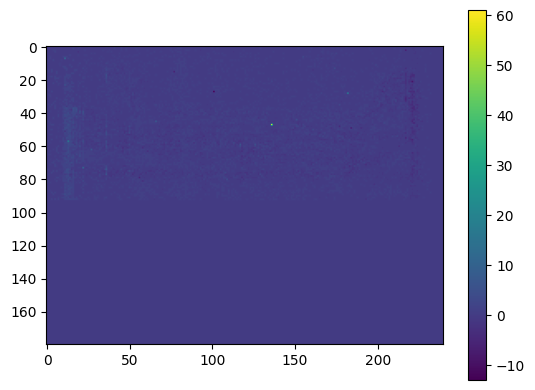

In [22]:
import matplotlib.pyplot as plt

img = np.zeros((height, width), dtype=float)

for i in range(len(events)):
    y_val = y[i]
    x_val = x[i]
    if polarity[i] == 1:
        img[y_val, x_val] += 1
    else:
        img[y_val, x_val] -= 1

plt.imshow(img)
plt.colorbar()